# Evaluación de cola por máquina

Este notebook reutiliza los cinco modelos y el test cronológico de `ModelEvaluationDataMining.ipynb`. Para comparar los modelos en las mismas observaciones, usa la intersección de filas de test con predicción disponible para todos. Después filtra esas filas por máquina y agrupa por día: tanto el valor real de `pct_posible_cola` como la probabilidad predicha de cola se promedian y se muestran como porcentaje.

Cada gráfica corresponde a un modelo. Cada máquina tiene un color propio: línea sólida para el valor real y línea discontinua del mismo color para la predicción.

## Preparar los datos y obtener predicciones

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from setup import common_test_rows, load_test_data, prepare_models

data = load_test_data()
models, predictions = prepare_models(data)

# Mantiene el mismo conjunto de filas para que la comparación entre modelos sea justa.
common_rows = common_test_rows(data, predictions)
print(f"Filas de test compartidas: {len(common_rows):,} de {len(data.test):,}")

Datos: 179,850 filas; train=125,894, validación=26,978, test=26,978
Test cronológico: 2025-06-27 15:30:00 -> 2025-12-31 23:30:00
Modelos disponibles: ['gru_E2_w48.keras', 'gru_E2_w48_scaler.joblib', 'logistic_regresion.keras', 'lstm_model.keras', 'mlp_classifier.joblib', 'tcn_classification_base_w48.keras']


c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to

Variables de entrada: {'Regresión logística': 25, 'LSTM': (24, 29), 'GRU/TCN': (48, 27), 'MLPClassifier': 41}
Filas de test con predicción por modelo: {'GRU': 26978, 'TCN': 26978, 'LSTM': 26978, 'Regresión logística': 26978, 'MLPClassifier': 26978}
Filas de test compartidas: 26,978 de 26,978


## Comparación diaria por máquina

Las salidas de estos modelos son probabilidades de cola, no regresiones directas del porcentaje. Al promediarlas por día se obtiene el porcentaje diario predicho de observaciones con cola; se compara con el promedio diario real de `pct_posible_cola`.

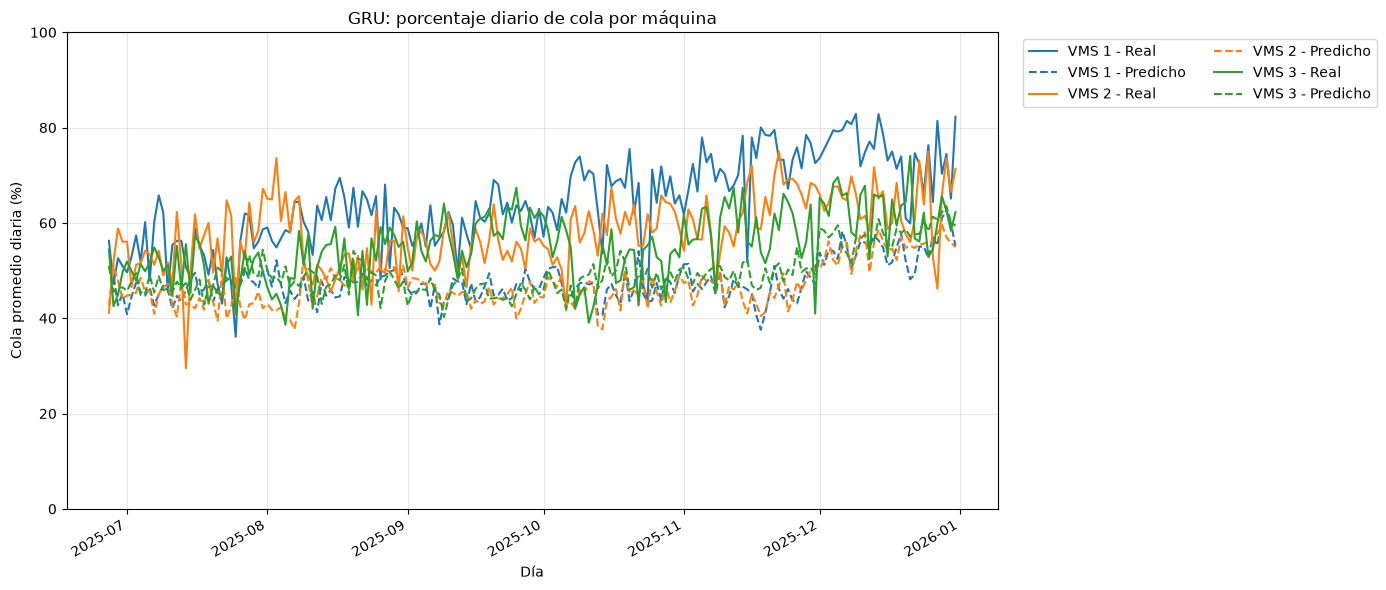

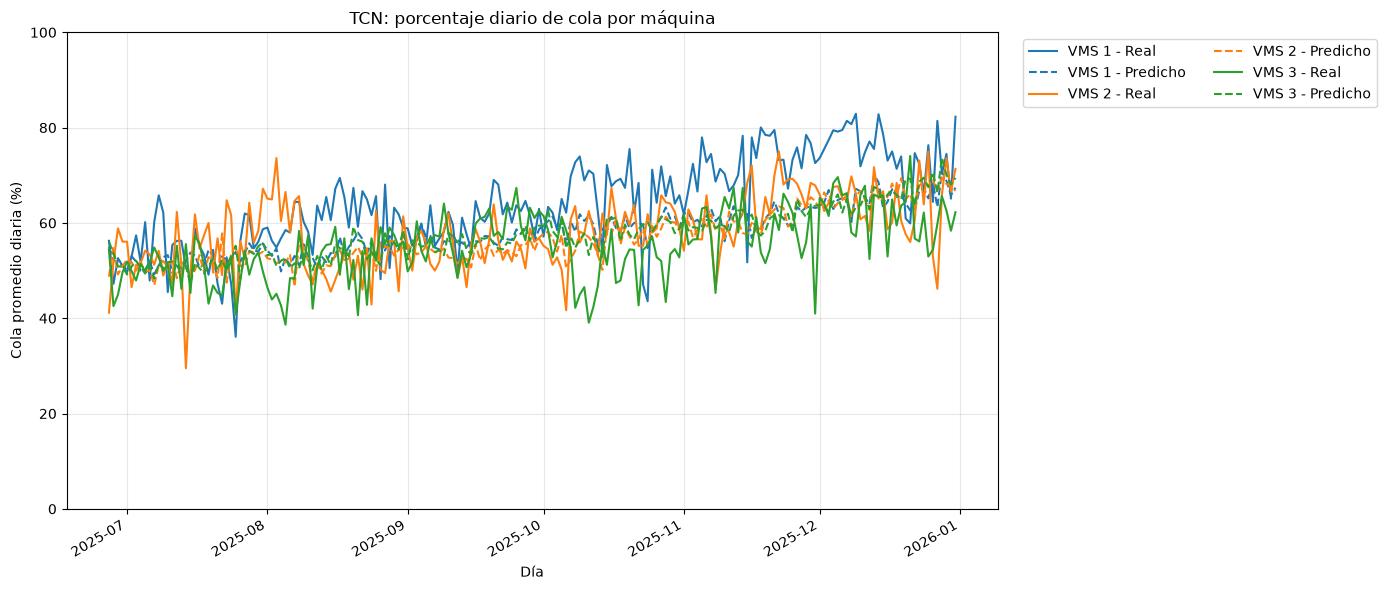

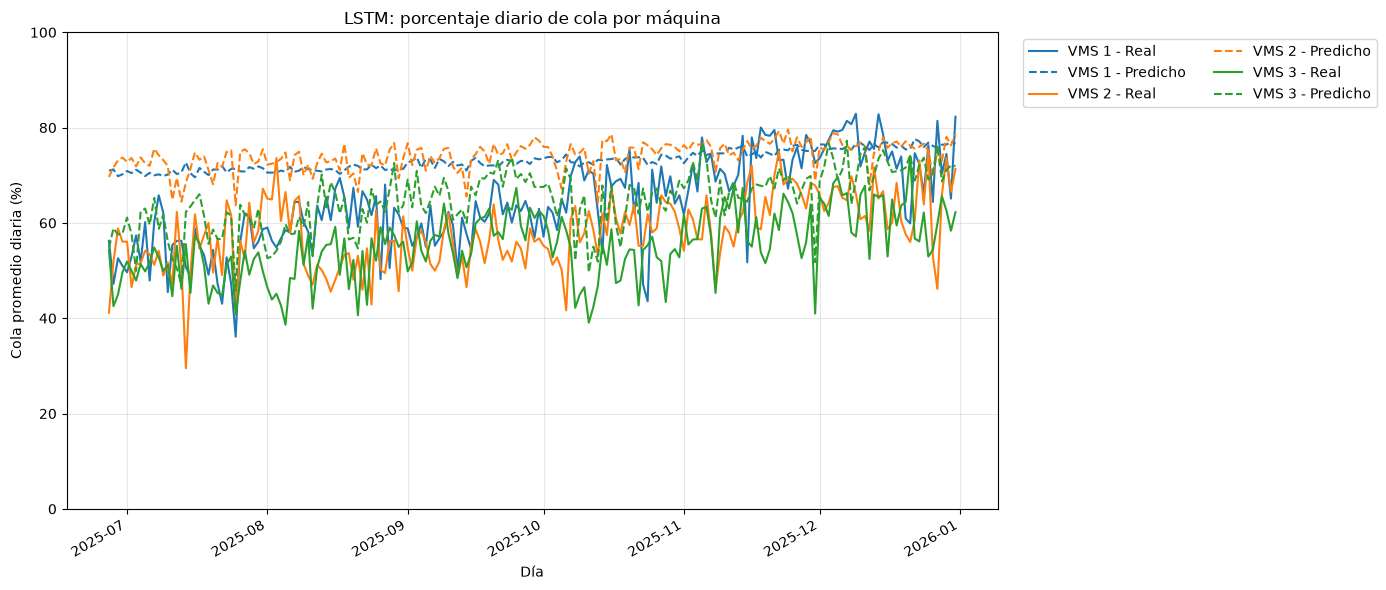

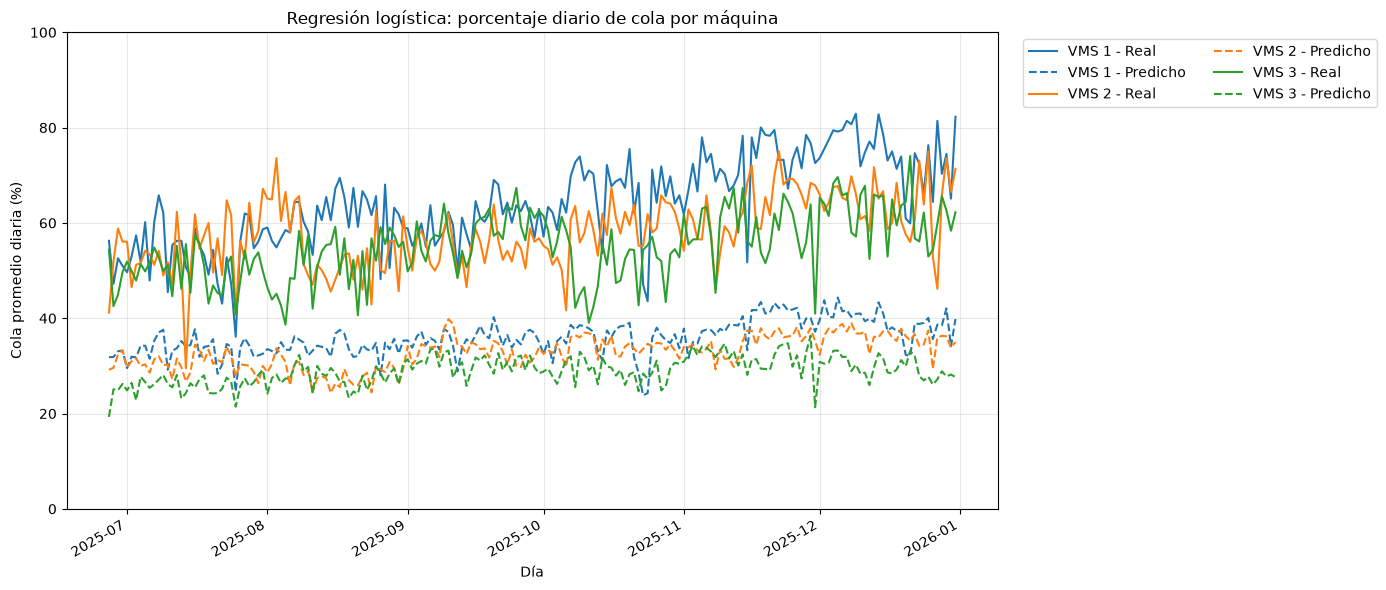

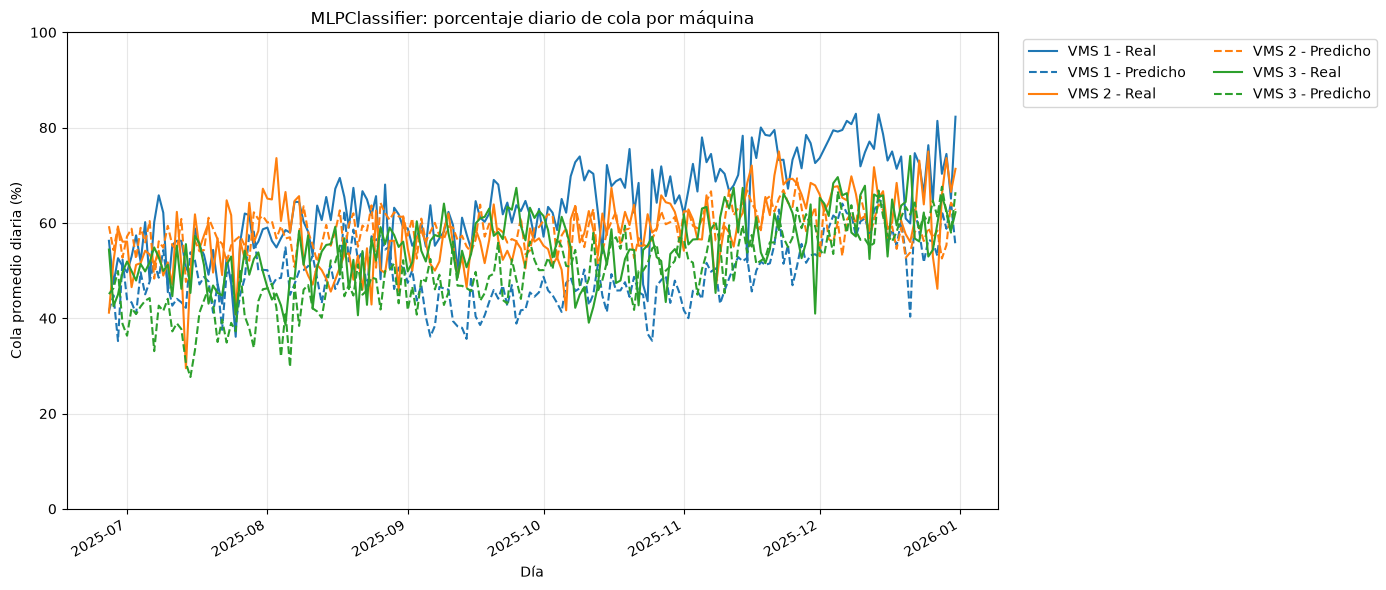

In [10]:
test_rows = (
    data.full_data.set_index("__row_id__")
    .loc[common_rows, ["bloque_tiempo", "ms", data.target]]
    .rename(columns={data.target: "Real"})
    .copy()
)
test_rows["Dia"] = pd.to_datetime(test_rows["bloque_tiempo"]).dt.floor("D")

machine_names = sorted(test_rows["ms"].dropna().unique())
colors = plt.get_cmap("tab10")

for model_name, model_scores in predictions.items():
    model_rows = test_rows.copy()
    model_rows["Predicho"] = model_scores.reindex(common_rows).to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(14, 6))
    for machine_index, machine_name in enumerate(machine_names):
        # Separa cada máquina antes de calcular sus promedios diarios.
        machine_rows = model_rows.loc[model_rows["ms"] == machine_name]
        daily = (
            machine_rows.groupby("Dia")[["Real", "Predicho"]]
            .mean()
            .mul(100)
        )
        color = colors(machine_index)
        ax.plot(
            daily.index,
            daily["Real"],
            color=color,
            linestyle="-",
            label=f"{machine_name} - Real",
        )
        ax.plot(
            daily.index,
            daily["Predicho"],
            color=color,
            linestyle="--",
            label=f"{machine_name} - Predicho",
        )

    ax.set_title(f"{model_name}: porcentaje diario de cola por máquina")
    ax.set_xlabel("Día")
    ax.set_ylabel("Cola promedio diaria (%)")
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()